In [3]:
import importlib
import src.modeling

importlib.reload(src.modeling)

from src.modeling import make_preprocessor, make_models

print("Imports successful!")

Imports successful!


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import time

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import build_features
from src.modeling import make_preprocessor, make_models
from src.evaluation import regression_metrics

DATA_DIR = PROJECT_ROOT / "data"

df = pd.read_csv(
    DATA_DIR / "train-test.csv",
    parse_dates=["date"]
)

print("Dataset:", df.shape)


Dataset: (48000, 14)


In [5]:

validation_months = [
    "2025-08-01",
    "2025-09-01",
    "2025-10-01"
]

experiments = []


In [6]:

for month in validation_months:

    start = pd.Timestamp(month)
    end = start + pd.DateOffset(months=1)

    # 1. Chronological split
    train_raw = df[df["date"] < start].copy()

    holdout_raw = df[
        (df["date"] >= start) &
        (df["date"] < end)
    ].copy()

    assert train_raw["date"].max() < holdout_raw["date"].min()

    # 2. Feature engineering
    X_train = build_features(train_raw)
    y_train = train_raw["posted_rate"]

    X_holdout = build_features(holdout_raw)
    y_holdout = holdout_raw["posted_rate"]

    # 3. Fit preprocessing ONLY on training data
    preprocessor = make_preprocessor(X_train)

    X_train_ready = preprocessor.fit_transform(X_train)
    X_holdout_ready = preprocessor.transform(X_holdout)

    print(f"\nHoldout month: {start.strftime('%Y-%m')}")
    print("Training loads:", len(train_raw))
    print("Holdout loads:", len(holdout_raw))

    # 4. Train and evaluate each model
    for name, model in make_models().items():

        start_time = time.perf_counter()

        model.fit(X_train_ready, y_train)

        predictions = model.predict(X_holdout_ready)

        training_seconds = (
            time.perf_counter() - start_time
        )

        metrics = regression_metrics(
            y_holdout,
            predictions
        )

        experiments.append({
            "Month": start.strftime("%Y-%m"),
            "Model": name,
            "Train Rows": len(train_raw),
            "Holdout Rows": len(holdout_raw),
            "Seconds": round(training_seconds, 2),
            **metrics
        })

        print(
            f"{name}: "
            f"MAE=${metrics['MAE']:.2f}, "
            f"WAPE={metrics['WAPE (%)']:.2f}%"
        )



Holdout month: 2025-08
Training loads: 33718
Holdout loads: 4759


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM: MAE=$94.64, WAPE=4.05%
XGBoost: MAE=$99.46, WAPE=4.25%
CatBoost: MAE=$99.17, WAPE=4.24%

Holdout month: 2025-09
Training loads: 38477
Holdout loads: 4670


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM: MAE=$108.15, WAPE=4.49%
XGBoost: MAE=$110.07, WAPE=4.57%
CatBoost: MAE=$108.92, WAPE=4.53%

Holdout month: 2025-10
Training loads: 43147
Holdout loads: 4853


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM: MAE=$112.70, WAPE=4.74%
XGBoost: MAE=$111.94, WAPE=4.71%
CatBoost: MAE=$109.60, WAPE=4.61%


In [7]:

results_df = pd.DataFrame(experiments)

display(
    results_df.sort_values(
        ["Month", "MAE"]
    )
)


,Month,Model,Train Rows,Holdout Rows,Seconds,MAE,RMSE,WAPE (%),R2
0,2025-08,LightGBM,33718,4759,2.47,94.64,614.48,4.05,0.8264
2,2025-08,CatBoost,33718,4759,0.69,99.17,614.69,4.24,0.8263
1,2025-08,XGBoost,33718,4759,1.52,99.46,614.89,4.25,0.8262
3,2025-09,LightGBM,38477,4670,2.43,108.15,617.55,4.49,0.8357
5,2025-09,CatBoost,38477,4670,0.70,108.92,617.60,4.53,0.8356
4,2025-09,XGBoost,38477,4670,1.67,110.07,618.63,4.57,0.8351
8,2025-10,CatBoost,43147,4853,0.80,109.60,647.29,4.61,0.8207
7,2025-10,XGBoost,43147,4853,1.78,111.94,647.75,4.71,0.8204
6,2025-10,LightGBM,43147,4853,2.49,112.70,647.35,4.74,0.8206


In [8]:

summary = (
    results_df.groupby("Model", as_index=False)
    .agg(
        average_MAE=("MAE", "mean"),
        worst_month_MAE=("MAE", "max"),
        average_RMSE=("RMSE", "mean"),
        average_WAPE=("WAPE (%)", "mean"),
        average_R2=("R2", "mean"),
        average_seconds=("Seconds", "mean")
    )
    .round(2)
    .sort_values("average_MAE")
)

display(summary)


,Model,average_MAE,worst_month_MAE,average_RMSE,average_WAPE,average_R2,average_seconds
1,LightGBM,105.16,112.70,626.46,4.43,0.83,2.46
0,CatBoost,105.90,109.60,626.53,4.46,0.83,0.73
2,XGBoost,107.16,111.94,627.09,4.51,0.83,1.66


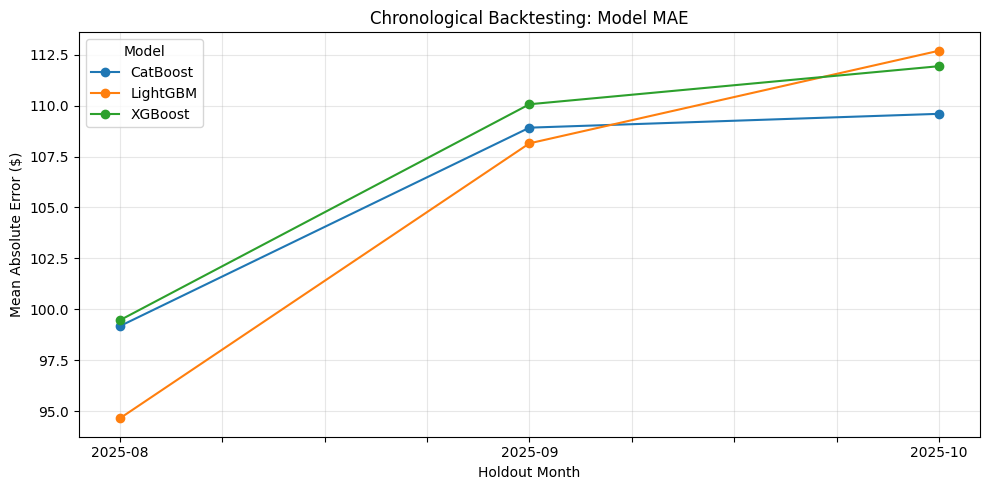

In [9]:

monthly_mae = results_df.pivot(
    index="Month",
    columns="Model",
    values="MAE"
)

monthly_mae.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Chronological Backtesting: Model MAE")
plt.xlabel("Holdout Month")
plt.ylabel("Mean Absolute Error ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

results_df.to_csv(
    REPORTS_DIR / "model_comparison.csv",
    index=False
)

print("Experiment results saved!")


Experiment results saved!


In [11]:

feature_experiments = []

feature_sets = {
    "Common": False,
    "Full": True
}

for month in validation_months:

    start = pd.Timestamp(month)
    end = start + pd.DateOffset(months=1)

    train_raw = df[df["date"] < start].copy()

    holdout_raw = df[
        (df["date"] >= start) &
        (df["date"] < end)
    ].copy()

    for feature_name, include_optional in feature_sets.items():

        X_train = build_features(
            train_raw,
            include_optional=include_optional
        )

        X_holdout = build_features(
            holdout_raw,
            include_optional=include_optional
        )

        y_train = train_raw["posted_rate"]
        y_holdout = holdout_raw["posted_rate"]

        preprocessor = make_preprocessor(X_train)

        X_train_ready = preprocessor.fit_transform(X_train)
        X_holdout_ready = preprocessor.transform(X_holdout)

        for model_name in ["LightGBM", "CatBoost"]:

            model = make_models()[model_name]

            model.fit(X_train_ready, y_train)

            predictions = model.predict(X_holdout_ready)

            metrics = regression_metrics(
                y_holdout, predictions
            )

            feature_experiments.append({
                "Month": month[:7],
                "Model": model_name,
                "Features": feature_name,
                "MAE": metrics["MAE"],
                "RMSE": metrics["RMSE"]
            })

ablation_df = pd.DataFrame(feature_experiments)

display(ablation_df)


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-pac

,Month,Model,Features,MAE,RMSE
0,2025-08,LightGBM,Common,94.64,614.48
1,2025-08,CatBoost,Common,99.17,614.69
2,2025-08,LightGBM,Full,123.71,617.43
3,2025-08,CatBoost,Full,102.96,614.39
4,2025-09,LightGBM,Common,108.15,617.55
5,2025-09,CatBoost,Common,108.92,617.60
6,2025-09,LightGBM,Full,108.22,618.83
7,2025-09,CatBoost,Full,114.19,620.12
8,2025-10,LightGBM,Common,112.70,647.35
9,2025-10,CatBoost,Common,109.60,647.29


In [12]:

ablation_summary = (
    ablation_df
    .groupby(["Model", "Features"])
    .agg(
        average_MAE=("MAE", "mean"),
        worst_MAE=("MAE", "max"),
        average_RMSE=("RMSE", "mean")
    )
    .round(2)
    .sort_values("average_MAE")
)

display(ablation_summary)


average_MAE  worst_MAE  average_RMSE
Model    Features                                      
LightGBM Common         105.16     112.70        626.46
CatBoost Common         105.90     109.60        626.53
         Full           111.19     116.41        627.08
LightGBM Full           115.93     123.71        627.87

In [13]:

geo_cols = [
    "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon"
]

market_cols = ["market_index", "quote_signal"]

group_results = []

for month in validation_months:

    start = pd.Timestamp(month)
    end = start + pd.DateOffset(months=1)

    train_raw = df[df["date"] < start].copy()

    holdout_raw = df[
        (df["date"] >= start) &
        (df["date"] < end)
    ].copy()

    X_train_full = build_features(
        train_raw, include_optional=True
    )

    X_holdout_full = build_features(
        holdout_raw, include_optional=True
    )

    configurations = {
        "Common + Geography": market_cols,
        "Common + Market": geo_cols
    }

    for feature_name, columns_to_drop in configurations.items():

        X_train = X_train_full.drop(
            columns=columns_to_drop
        )

        X_holdout = X_holdout_full.drop(
            columns=columns_to_drop
        )

        preprocessor = make_preprocessor(X_train)

        X_train_ready = preprocessor.fit_transform(X_train)
        X_holdout_ready = preprocessor.transform(X_holdout)

        for model_name in ["LightGBM", "CatBoost"]:

            model = make_models()[model_name]

            model.fit(
                X_train_ready,
                train_raw["posted_rate"]
            )

            predictions = model.predict(X_holdout_ready)

            metrics = regression_metrics(
                holdout_raw["posted_rate"],
                predictions
            )

            group_results.append({
                "Month": month[:7],
                "Model": model_name,
                "Features": feature_name,
                "MAE": metrics["MAE"]
            })

group_df = pd.DataFrame(group_results)

display(
    group_df.groupby(["Model", "Features"])
    .agg(
        average_MAE=("MAE", "mean"),
        worst_MAE=("MAE", "max")
    ).round(2)
)


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-pac

average_MAE  worst_MAE
Model    Features                                  
CatBoost Common + Geography       104.00     110.13
         Common + Market          111.16     111.96
LightGBM Common + Geography       103.60     111.75
         Common + Market          119.46     134.01

In [14]:

tuning_configs = {
    "Baseline": {},

    "Conservative": {
        "num_leaves": 15,
        "min_child_samples": 100,
        "reg_lambda": 5.0
    },

    "Higher Capacity": {
        "num_leaves": 45,
        "min_child_samples": 40,
        "reg_lambda": 3.0
    }
}


In [15]:

tuning_results = []

for month in validation_months:

    start = pd.Timestamp(month)
    end = start + pd.DateOffset(months=1)

    train_raw = df[df["date"] < start].copy()

    holdout_raw = df[
        (df["date"] >= start) &
        (df["date"] < end)
    ].copy()

    for feature_set in ["Common", "Geography"]:

        use_geo = feature_set == "Geography"

        X_train = build_features(
            train_raw,
            include_optional=use_geo
        )

        X_holdout = build_features(
            holdout_raw,
            include_optional=use_geo
        )

        if use_geo:
            X_train = X_train.drop(
                columns=["market_index", "quote_signal"]
            )
            X_holdout = X_holdout.drop(
                columns=["market_index", "quote_signal"]
            )

        preprocessor = make_preprocessor(X_train)

        X_train_ready = preprocessor.fit_transform(X_train)
        X_holdout_ready = preprocessor.transform(X_holdout)

        for config_name, params in tuning_configs.items():

            model = make_models()["LightGBM"]
            model.set_params(**params)

            model.fit(
                X_train_ready,
                train_raw["posted_rate"]
            )

            predictions = model.predict(X_holdout_ready)

            metrics = regression_metrics(
                holdout_raw["posted_rate"],
                predictions
            )

            tuning_results.append({
                "Month": month[:7],
                "Features": feature_set,
                "Configuration": config_name,
                "MAE": metrics["MAE"],
                "RMSE": metrics["RMSE"]
            })

tuning_df = pd.DataFrame(tuning_results)


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-pac

In [16]:


tuning_summary = (
    tuning_df
    .groupby(["Features", "Configuration"])
    .agg(
        average_MAE=("MAE", "mean"),
        worst_MAE=("MAE", "max"),
        average_RMSE=("RMSE", "mean")
    )
    .round(2)
    .sort_values("average_MAE")
)

display(tuning_summary)


average_MAE  worst_MAE  average_RMSE
Features  Configuration                                        
Geography Higher Capacity       103.12     112.17        626.18
          Baseline              103.60     111.75        625.74
Common    Higher Capacity       104.26     113.44        626.39
Geography Conservative          105.02     112.83        625.92
Common    Baseline              105.16     112.70        626.46
          Conservative          107.15     113.28        626.67

In [17]:

start = pd.Timestamp("2025-10-01")

train_raw = df[df["date"] < start].copy()
holdout_raw = df[df["date"] >= start].copy()

market_cols = ["market_index", "quote_signal"]

X_train = build_features(
    train_raw, include_optional=True
).drop(columns=market_cols)

X_holdout = build_features(
    holdout_raw, include_optional=True
).drop(columns=market_cols)

y_train = train_raw["posted_rate"]
y_holdout = holdout_raw["posted_rate"]

preprocessor = make_preprocessor(X_train)

X_train_ready = preprocessor.fit_transform(X_train)
X_holdout_ready = preprocessor.transform(X_holdout)

model = make_models()["LightGBM"]

model.set_params(
    num_leaves=45,
    min_child_samples=40,
    reg_lambda=3.0
)

model.fit(X_train_ready, y_train)

predictions = model.predict(X_holdout_ready)

print(regression_metrics(y_holdout, predictions))


{'MAE': 112.17, 'RMSE': np.float64(647.26), 'WAPE (%)': np.float64(4.71), 'R2': 0.8207}


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,feature,importance
0,numerical__distance,3534
7,numerical__days_since_2025_01_01,2509
1,numerical__weight,1850
9,numerical__pickup_lat,1139
11,numerical__delivery_lat,1124
12,numerical__delivery_lon,1060
10,numerical__pickup_lon,1004
141,categorical__equipment_Dry Van,732
5,numerical__weekday,633
143,categorical__equipment_Reefer,308


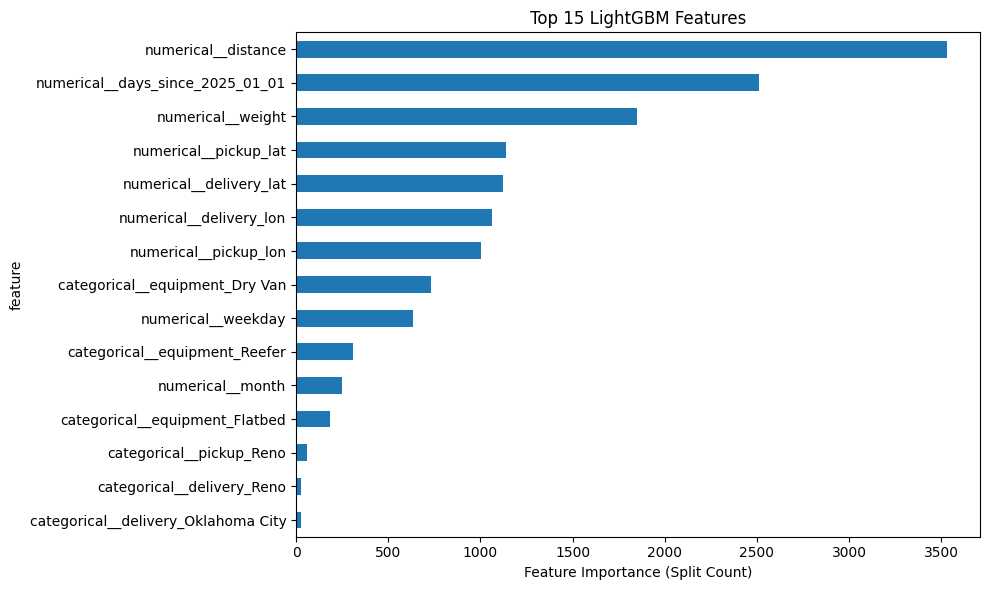

In [18]:

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

display(importance_df.head(15))

importance_df.head(15).sort_values(
    "importance"
).plot(
    x="feature",
    y="importance",
    kind="barh",
    figsize=(10, 6),
    legend=False,
    title="Top 15 LightGBM Features"
)

plt.xlabel("Feature Importance (Split Count)")
plt.tight_layout()
plt.show()


In [19]:

error_df = holdout_raw[
    ["load_id", "pickup", "delivery",
     "distance", "equipment", "posted_rate"]
].copy()

error_df["predicted_rate"] = predictions

error_df["absolute_error"] = (
    error_df["posted_rate"]
    - error_df["predicted_rate"]
).abs()

error_df["percentage_error"] = (
    error_df["absolute_error"]
    / error_df["posted_rate"].abs()
) * 100

print("Largest prediction errors:")

display(
    error_df.sort_values(
        "absolute_error", ascending=False
    ).head(10)
)

print("\nError distribution:")

display(
    error_df["absolute_error"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)


Largest prediction errors:


,load_id,pickup,delivery,distance,equipment,posted_rate,predicted_rate,absolute_error,percentage_error
43539,TR-043540,Milwaukee,Bakersfield,1893.0,Dry Van,17514.11,3649.286950,13864.823050,79.163732
46213,TR-046214,Columbia,Tucson,2023.4,Flatbed,17893.17,4304.439584,13588.730416,75.943672
47298,TR-047299,Boston,Bakersfield,2979.1,Reefer,19110.30,6046.070069,13064.229931,68.362244
46516,TR-046517,Toledo,Albuquerque,1684.3,Reefer,14784.38,3674.000580,11110.379420,75.149444
47536,TR-047537,Los Angeles,Richmond,2782.4,Dry Van,15003.55,4912.318981,10091.231019,67.258956
46366,TR-046367,Bakersfield,Columbia,2251.9,Dry Van,14403.14,4361.927965,10041.212035,69.715437
44267,TR-044268,Albany,Albuquerque,2492.6,Dry Van,14425.42,4417.714091,10007.705909,69.375491
43384,TR-043385,Lexington,Lubbock,1187.0,Dry Van,11696.44,2394.935754,9301.504246,79.524233
43302,TR-043303,Atlanta,Phoenix,2083.1,Reefer,13894.55,4689.636617,9204.913383,66.248374
47586,TR-047587,Corpus Christi,Las Vegas,1383.3,Flatbed,11596.28,3032.731017,8563.548983,73.847380



Error distribution:


count     4853.000000
mean       112.168533
std        637.535892
min          0.002365
50%         35.586263
90%        128.721776
95%        183.443733
99%       1809.837614
max      13864.823050
Name: absolute_error, dtype: float64

In [20]:

threshold = error_df["absolute_error"].quantile(0.99)

extreme_errors = error_df[
    error_df["absolute_error"] >= threshold
]

total_error = error_df["absolute_error"].sum()
extreme_error = extreme_errors["absolute_error"].sum()

print("Extreme error count:", len(extreme_errors))
print(
    "Share of total absolute error:",
    round(extreme_error / total_error * 100, 2), "%"
)


Extreme error count: 49
Share of total absolute error: 48.9 %


In [21]:

train_raw = df[
    df["date"] < "2025-10-01"
].copy()

holdout_raw = df[
    df["date"] >= "2025-10-01"
].copy()

historical_cities = (
    set(train_raw["pickup"]) |
    set(train_raw["delivery"])
)

october_cities = (
    set(holdout_raw["pickup"]) |
    set(holdout_raw["delivery"])
)

eligible_cities = sorted(
    historical_cities & october_cities
)

rng = np.random.default_rng(42)

cold_cities = set(
    rng.choice(eligible_cities, size=8, replace=False)
)

print("Selected unseen-city simulation:", sorted(cold_cities))


Selected unseen-city simulation: [np.str_('Bakersfield'), np.str_('Hartford'), np.str_('Memphis'), np.str_('New York'), np.str_('San Antonio'), np.str_('Toledo'), np.str_('Tulsa'), np.str_('Washington')]


In [22]:

train_mask = ~(
    train_raw["pickup"].isin(cold_cities) |
    train_raw["delivery"].isin(cold_cities)
)

test_mask = (
    holdout_raw["pickup"].isin(cold_cities) |
    holdout_raw["delivery"].isin(cold_cities)
)

cold_train = train_raw.loc[train_mask].copy()
cold_holdout = holdout_raw.loc[test_mask].copy()

print("Remaining training loads:", len(cold_train))
print("Cold-city test loads:", len(cold_holdout))

assert len(cold_holdout) > 0

assert not (
    cold_train["pickup"].isin(cold_cities) |
    cold_train["delivery"].isin(cold_cities)
).any()


Remaining training loads: 31873
Cold-city test loads: 1288


In [23]:

def geo_features(data):
    return build_features(
        data,
        include_optional=True
    ).drop(columns=["market_index", "quote_signal"])


def train_and_predict(training_data, test_data):

    X_tr = geo_features(training_data)
    y_tr = training_data["posted_rate"]

    X_te = geo_features(test_data)

    prep = make_preprocessor(X_tr)

    X_tr_ready = prep.fit_transform(X_tr)
    X_te_ready = prep.transform(X_te)

    regressor = make_models()["LightGBM"]

    regressor.set_params(
        num_leaves=45,
        min_child_samples=40,
        reg_lambda=3.0
    )

    regressor.fit(X_tr_ready, y_tr)

    return regressor.predict(X_te_ready)


# Normal training: all earlier cities available
normal_predictions = train_and_predict(
    train_raw, cold_holdout
)

# Stress test: eight cities excluded from training
cold_predictions = train_and_predict(
    cold_train, cold_holdout
)

actual = cold_holdout["posted_rate"]

comparison = pd.DataFrame([
    {
        "Experiment": "Normal training",
        **regression_metrics(actual, normal_predictions)
    },
    {
        "Experiment": "Unseen-city training",
        **regression_metrics(actual, cold_predictions)
    }
])

display(comparison)


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Experiment,MAE,RMSE,WAPE (%),R2
0,Normal training,108.77,722.69,4.49,0.8009
1,Unseen-city training,111.21,722.44,4.59,0.8010
